In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import joblib

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

In [2]:
PROJECT_ROOT = Path.cwd().parent

MODELING_DATA_DIR = PROJECT_ROOT / "data" / "processed" / "modeling"
TABLES_DIR = PROJECT_ROOT / "reports" / "tables"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
MODELS_DIR = PROJECT_ROOT / "models"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [3]:
X_train = joblib.load(MODELING_DATA_DIR / "X_train_target_diag.joblib")
X_val = joblib.load(MODELING_DATA_DIR / "X_val_target_diag.joblib")
X_test = joblib.load(MODELING_DATA_DIR / "X_test_target_diag.joblib")

y_train = joblib.load(MODELING_DATA_DIR / "y_train.joblib")
y_val = joblib.load(MODELING_DATA_DIR / "y_val.joblib")
y_test = joblib.load(MODELING_DATA_DIR / "y_test.joblib")

X_train.shape, X_val.shape

((59604, 168), (19868, 168))

bootstrap = True - svako stablo dobija slucajan uzorak od ukupnog broja instanci sa ponavljanjem

In [4]:
param_distributions = {
    "n_estimators": [100, 200, 300],
    "max_depth": [10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [2, 5, 10],
    "max_features": ["sqrt", "log2"],
    "bootstrap": [True]
}

In [5]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [6]:
base_rf_model = RandomForestClassifier(
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=base_rf_model,
    param_distributions=param_distributions,
    n_iter=10,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    return_train_score=True
)

In [7]:
random_search.fit(
    X_train,
    y_train
)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bootstrap': [True], 'max_depth': [10, 20, ...], 'max_features': ['sqrt', 'log2'], 'min_samples_leaf': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",2
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`

In [8]:
cv_results = pd.DataFrame(random_search.cv_results_)

cv_results_sorted = cv_results.sort_values(
    by="mean_test_score",
    ascending=False
)

cv_results_sorted[
    [
        "mean_test_score",
        "std_test_score",
        "mean_train_score",
        "std_train_score",
        "params"
    ]
].head(10)

,mean_test_score,std_test_score,mean_train_score,std_train_score,params
2,0.285399,0.005240,0.522320,0.003479,"{'n_estimators': 300, 'min_samples_split': 5, ..."
4,0.280820,0.009199,0.470880,0.005798,"{'n_estimators': 200, 'min_samples_split': 5, ..."
9,0.280715,0.007496,0.543003,0.005696,"{'n_estimators': 100, 'min_samples_split': 2, ..."
6,0.280273,0.005708,0.394681,0.003024,"{'n_estimators': 300, 'min_samples_split': 2, ..."
0,0.280246,0.007020,0.415913,0.002680,"{'n_estimators': 300, 'min_samples_split': 5, ..."
8,0.278245,0.005868,0.394599,0.002948,"{'n_estimators': 200, 'min_samples_split': 2, ..."
5,0.273272,0.004741,0.330744,0.002045,"{'n_estimators': 300, 'min_samples_split': 2, ..."
7,0.272153,0.005160,0.310372,0.001237,"{'n_estimators': 100, 'min_samples_split': 10,..."
3,0.256134,0.011889,0.788954,0.012179,"{'n_estimators': 200, 'min_samples_split': 2, ..."
1,0.204361,0.007051,0.963272,0.002807,"{'n_estimators': 200, 'min_samples_split': 2, ..."


In [9]:
cv_results_sorted.to_csv(
    TABLES_DIR / "random_forest_randomized_search_cv_results.csv",
    index=False
)

In [10]:
best_rf_model = random_search.best_estimator_
best_rf_params = random_search.best_params_
best_rf_cv_f1 = random_search.best_score_

best_rf_params, best_rf_cv_f1

({'n_estimators': 300,
  'min_samples_split': 5,
  'min_samples_leaf': 10,
  'max_features': 'sqrt',
  'max_depth': 30,
  'bootstrap': True},
 np.float64(0.2853992755224177))

Evaluacija modela na validacionom skupu

In [11]:
y_val_proba = best_rf_model.predict_proba(X_val)[:, 1]
y_val_pred = best_rf_model.predict(X_val)

optimized_rf_validation_results = pd.DataFrame([{
    "model": "Optimized Random Forest",
    "threshold": 0.5,
    "accuracy": round(accuracy_score(y_val, y_val_pred), 4),
    "precision": round(
        precision_score(y_val, y_val_pred, zero_division=0),
        4
    ),
    "recall": round(recall_score(y_val, y_val_pred), 4),
    "f1": round(f1_score(y_val, y_val_pred), 4),
    "roc_auc": round(roc_auc_score(y_val, y_val_proba), 4)
}])

optimized_rf_validation_results

,model,threshold,accuracy,precision,recall,f1,roc_auc
0,Optimized Random Forest,0.5,0.7316,0.204,0.4675,0.2841,0.678


In [12]:
optimized_rf_validation_results.to_csv(
    TABLES_DIR / "optimized_random_forest_validation_results.csv",
    index=False
)

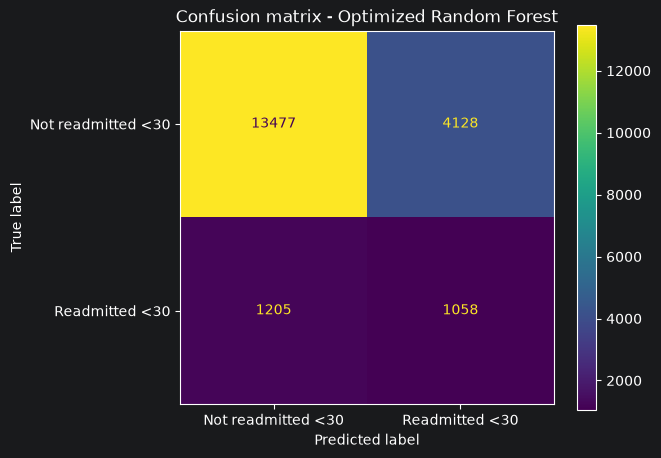

In [13]:
cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not readmitted <30", "Readmitted <30"]
)

disp.plot()
plt.title("Confusion matrix - Optimized Random Forest")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "confusion_matrix_optimized_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

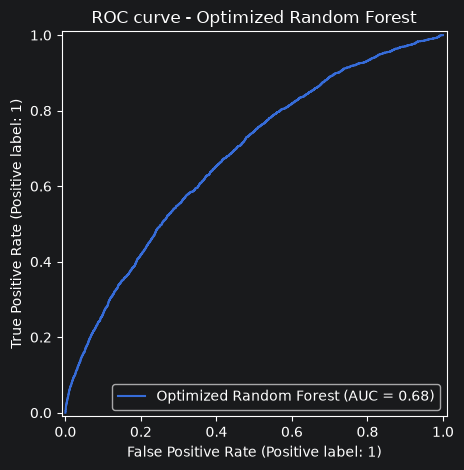

In [14]:
RocCurveDisplay.from_predictions(
    y_val,
    y_val_proba,
    name="Optimized Random Forest"
)

plt.title("ROC curve - Optimized Random Forest")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "roc_curve_optimized_random_forest.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

## Threshold tuning
Podrazumevani prag klasifikacije iznosi 0.5, ali on ne mora davati najbolji rezultat na neuravnotezenom skupu podataka.<br>
 Prag se zato bira na validacionom skupu tako da se maksimizuje f1 score, koji predstavlja balans izmedju preciznosti i odziva.

In [15]:
threshold_results = []

thresholds = np.arange(0.10, 0.91, 0.01)

for threshold in thresholds:
    y_val_pred_threshold = (y_val_proba >= threshold).astype(int)

    threshold_results.append({
        "threshold": round(threshold, 2),
        "accuracy": accuracy_score(y_val, y_val_pred_threshold),
        "precision": precision_score(
            y_val,
            y_val_pred_threshold,
            zero_division=0
        ),
        "recall": recall_score(y_val, y_val_pred_threshold),
        "f1": f1_score(y_val, y_val_pred_threshold)
    })

threshold_results = pd.DataFrame(threshold_results)

In [16]:
threshold_results_sorted = threshold_results.sort_values(
    by="f1",
    ascending=False
)

threshold_results_sorted.head(10)

,threshold,accuracy,precision,recall,f1
39,0.49,0.711899,0.199827,0.509059,0.286996
38,0.48,0.689702,0.193239,0.543084,0.285052
40,0.50,0.731578,0.204011,0.467521,0.284065
37,0.47,0.665341,0.186714,0.577552,0.282198
41,0.51,0.751460,0.209933,0.427751,0.281641
42,0.52,0.767314,0.214562,0.391958,0.277317
36,0.46,0.640276,0.179696,0.605391,0.277132
44,0.54,0.797010,0.233112,0.341582,0.277111
43,0.53,0.782011,0.221893,0.364560,0.275874
35,0.45,0.614355,0.174877,0.641626,0.274844


In [17]:
best_threshold = threshold_results_sorted.iloc[0]["threshold"]

best_threshold

np.float64(0.49)

Evaluacija optimizovanog RF na test skupu.

In [18]:
y_test_proba = best_rf_model.predict_proba(X_test)[:, 1]

y_test_pred_best_threshold = (
    y_test_proba >= best_threshold
).astype(int)

optimized_test_accuracy = accuracy_score(
    y_test,
    y_test_pred_best_threshold
)

optimized_test_precision = precision_score(
    y_test,
    y_test_pred_best_threshold,
    zero_division=0
)

optimized_test_recall = recall_score(
    y_test,
    y_test_pred_best_threshold,
    zero_division=0
)

optimized_test_f1 = f1_score(
    y_test,
    y_test_pred_best_threshold,
    zero_division=0
)

optimized_test_roc_auc = roc_auc_score(
    y_test,
    y_test_proba
)

print(f"Threshold: {best_threshold:.4f}")
print(f"Accuracy:  {optimized_test_accuracy:.4f}")
print(f"Precision: {optimized_test_precision:.4f}")
print(f"Recall:    {optimized_test_recall:.4f}")
print(f"F1-score:  {optimized_test_f1:.4f}")
print(f"ROC AUC:   {optimized_test_roc_auc:.4f}")

Threshold: 0.4900
Accuracy:  0.7094
Precision: 0.1962
Recall:    0.5007
F1-score:  0.2819
ROC AUC:   0.6752


Matrica konfuzije.

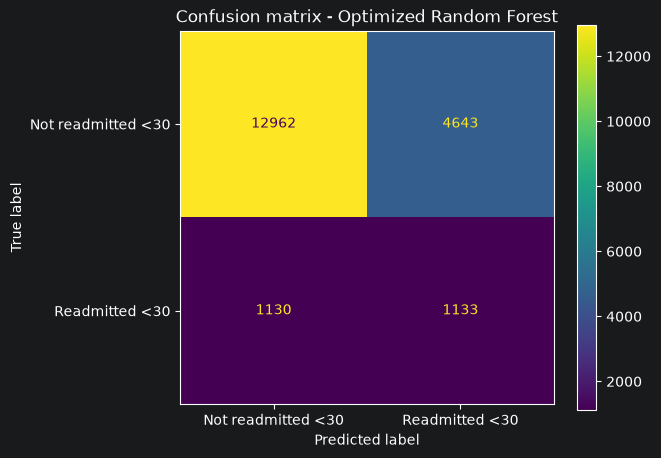

In [19]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred_best_threshold,
    display_labels=[
        "Not readmitted <30",
        "Readmitted <30"
    ]
)

plt.title(
    "Confusion matrix - Optimized Random Forest"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "optimized_random_forest_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

ROC kriva.

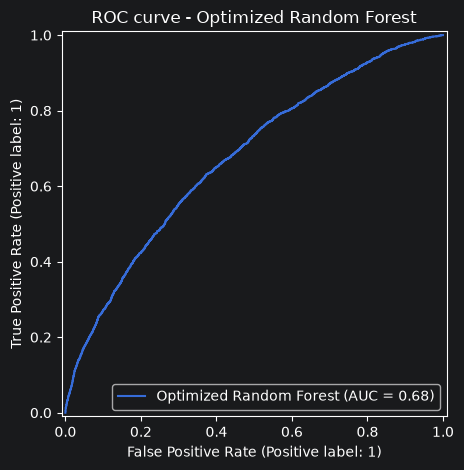

In [20]:
RocCurveDisplay.from_predictions(
    y_test,
    y_test_proba,
    name="Optimized Random Forest"
)

plt.title(
    "ROC curve - Optimized Random Forest"
)

plt.tight_layout()

plt.savefig(
    FIGURES_DIR /
    "optimized_random_forest_test_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [21]:
optimized_rf_test_results = pd.DataFrame([{
    "model": "Optimized Random Forest",
    "threshold": best_threshold,
    "accuracy": optimized_test_accuracy,
    "precision": optimized_test_precision,
    "recall": optimized_test_recall,
    "f1": optimized_test_f1,
    "roc_auc": optimized_test_roc_auc
}])

optimized_rf_test_results

,model,threshold,accuracy,precision,recall,f1,roc_auc
0,Optimized Random Forest,0.49,0.709432,0.196157,0.500663,0.281876,0.675169


In [22]:
optimized_rf_test_results.to_csv(
    TABLES_DIR /
    "optimized_random_forest_test_results.csv",
    index=False
)

In [23]:
joblib.dump(
    best_rf_model,
    MODELS_DIR / "optimized_random_forest_target_diag.joblib"
)

['C:\\Users\\user\\Documents\\MasterRad\\models\\optimized_random_forest_target_diag.joblib']